# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [3]:
ROLL_NO = 1024170151          # <-- your full roll number
NAME = "Harsh"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [4]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [5]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [6]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170151   Name: Harsh   Fingerprint: 53442183   Tickets: 13

Ticket_ID                                                                               Ticket_Text
      T01                                The password failed to open. It works on another computer.
      T02 I was locked out of the password when I use mobile hotspot. It works on another computer.
      T03                                      The password is showing an error. Please resolve it.
      T04               VPN is not working when I use mobile hotspot. It works on another computer.
      T05                       I was locked out of the laptop during the lab. It worked yesterday.
      T06                Wi-Fi crashes while opening during the lab. The same problem occurs again.
      T07                                               I can't login and I didn't change anything.
      T08                                                     I tried again... still no response!!!
      T09              

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [7]:
import pandas as pd

summary_rows = []
for _, row in df.iterrows():
    result = process_ticket(row["Ticket_Text"])
    summary_rows.append({
        "Ticket_ID": row["Ticket_ID"],
        "sentences": result["sentences"],
        "tokens": result["tokens"],
        "punctuation_tokens": result["punct"],
        "stopwords": result["stops"],
        "unique_tokens": sorted(set(result["tokens"])),
        "final_tokens": result["final"],
    })

all_tokens = [t for item in summary_rows for t in item["tokens"]]
all_punct = [t for item in summary_rows for t in item["punctuation_tokens"]]
all_stops = [t for item in summary_rows for t in item["stopwords"]]
all_final = [t for item in summary_rows for t in item["final_tokens"]]
summary_rows.append({
    "Ticket_ID": "TOTAL",
    "sentences": sum(len(item["sentences"]) for item in summary_rows[:-1]),
    "tokens": all_tokens,
    "punctuation_tokens": all_punct,
    "stopwords": all_stops,
    "unique_tokens": sorted(set(all_tokens)),
    "final_tokens": all_final,
})

summary_df = pd.DataFrame(summary_rows)
summary_df


,Ticket_ID,sentences,tokens,punctuation_tokens,stopwords,unique_tokens,final_tokens
0,T01,"[The password failed to open., It works on ano...","[the, password, failed, to, open, ., it, works...","[., .]","[the, to, it, on]","[., another, computer, failed, it, on, open, p...","[password, failed, open, works, another, compu..."
1,T02,[I was locked out of the password when I use m...,"[i, was, locked, out, of, the, password, when,...","[., .]","[i, was, out, of, the, when, i, it, on]","[., another, computer, hotspot, i, it, locked,...","[locked, password, use, mobile, hotspot, works..."
2,T03,"[The password is showing an error., Please res...","[the, password, is, showing, an, error, ., ple...","[., .]","[the, is, an, it]","[., an, error, is, it, password, please, resol...","[password, showing, error, please, resolve]"
3,T04,[VPN is not working when I use mobile hotspot....,"[vpn, is, not, working, when, i, use, mobile, ...","[., .]","[is, not, when, i, it, on]","[., another, computer, hotspot, i, is, it, mob...","[vpn, working, use, mobile, hotspot, works, an..."
4,T05,[I was locked out of the laptop during the lab...,"[i, was, locked, out, of, the, laptop, during,...","[., .]","[i, was, out, of, the, during, the, it]","[., during, i, it, lab, laptop, locked, of, ou...","[locked, laptop, lab, worked, yesterday]"
5,T06,"[Wi-Fi crashes while opening during the lab., ...","[wi-fi, crashes, while, opening, during, the, ...","[., .]","[while, during, the, the, same, again]","[., again, crashes, during, lab, occurs, openi...","[wi-fi, crashes, opening, lab, problem, occurs]"
6,T07,[I can't login and I didn't change anything.],"[i, ca, n't, login, and, i, did, n't, change, ...",[.],"[i, and, i, did]","[., and, anything, ca, change, did, i, login, ...","[ca, n't, login, n't, change, anything]"
7,T08,"[I tried again... still no response!!, !]","[i, tried, again, ..., still, no, response, !,...","[..., !, !, !]","[i, again, no]","[!, ..., again, i, no, response, still, tried]","[tried, still, response]"
8,T09,"[The student portal is running slowly., This i...","[the, student, portal, is, running, slowly, .,...","[., .]","[the, is, this, is]","[., is, portal, running, slowly, student, the,...","[student, portal, running, slowly, urgent]"
9,T10,[Call me on +91 98765 43210 or 0175-239-3201.],"[call, me, on, +91, 98765, 43210, or, 0175-239...",[.],"[me, on, or]","[+91, ., 0175-239-3201, 43210, 98765, call, me...","[call, +91, 98765, 43210, 0175-239-3201]"


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*
The non-word final tokens are mainly contraction fragments such as `n't`, `ca`, and `'s`. They appear because `word_tokenize` splits contractions at the apostrophe, so `can't` becomes `ca` + `n't`, `didn't` becomes `did` + `n't`, and possessives like `Rao's` contribute an apostrophe token or a possessive suffix. These are not normal dictionary words, but they are valid tokenization artifacts from informal ticket text.


---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [10]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re

email_pat = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
url_pat = r"(?:https?://|www\.)[^\s]+"
phone_pat = r"(?:\+?\d{1,3}[-\s]?)?(?:\(?\d{2,4}\)?[-\s]?){2,3}\d{3,4}"

regex_rows = []
for _, row in df.iterrows():
    text = row["Ticket_Text"]
    regex_rows.append({
        "Ticket_ID": row["Ticket_ID"],
        "long_words": re.findall(r"\b[A-Za-z]{6,}\b", text),
        "numbers": re.findall(r"\b\d+(?:\.\d+)+(?:\.\d+)*\b|\b\d+\b", text),
        "capitalized_words": re.findall(r"\b[A-Z][a-zA-Z]*\b", text),
        "vowel_words": re.findall(r"\b[AEIOUaeiou][A-Za-z']*\b", text),
        "masked_text": re.sub(phone_pat, "<PHONE>", re.sub(url_pat, "<URL>", re.sub(email_pat, "<EMAIL>", text))),
    })

regex_df = pd.DataFrame(regex_rows)
regex_df[["Ticket_ID", "long_words", "numbers", "capitalized_words", "vowel_words", "masked_text"]].head()

print("TEST_LINES regex check:")
for line in TEST_LINES:
    masked = re.sub(phone_pat, "<PHONE>", re.sub(url_pat, "<URL>", re.sub(email_pat, "<EMAIL>", line)))
    print(masked)


TEST_LINES regex check:
Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>
Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.
The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.


**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*
Out of 29 capitalized words in the ticket set, 22 are sentence-initial capitals. The remaining capitalized items are mostly proper nouns or acronyms such as `Wi`, `VPN`, `MATLAB`, `PCs`, and `Wi-Fi`.


---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [12]:
from nltk.tokenize import RegexpTokenizer, word_tokenize

my_pattern = r"(?:[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|(?:https?://|www\.)[^\s]+|(?:\+?\d{1,3}[-\s]?)?(?:\(?\d{2,4}\)?[-\s]?){2,3}\d{3,4}|\d+(?:\.\d+)+(?:\.\d+)*|[A-Za-z]+(?:['’][A-Za-z]+)?(?:-[A-Za-z]+)*)"
my_tokenizer = RegexpTokenizer(my_pattern)


def my_tokenize(text):
    return my_tokenizer.tokenize(text)

compare_rows = []
for _, row in df.iterrows():
    text = row["Ticket_Text"]
    my_tokens = my_tokenize(text)
    wd_tokens = word_tokenize(text)
    compare_rows.append({
        "Ticket_ID": row["Ticket_ID"],
        "my_tokenize": my_tokens,
        "word_tokenize": wd_tokens,
        "different": my_tokens != wd_tokens,
    })

compare_df = pd.DataFrame(compare_rows)
compare_df[compare_df["different"] == True][["Ticket_ID", "my_tokenize", "word_tokenize"]].head()

print("TEST_LINES:\n")
for line in TEST_LINES:
    print(f"TEXT: {line}")
    print("my_tokenize:", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))
    print("different:", my_tokenize(line) != word_tokenize(line))
    print()

print(f"Tickets tokenized differently: {compare_df['different'].sum()} / {len(compare_df)}")


TEST_LINES:

TEXT: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
my_tokenize: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
different: True

TEXT: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
my_tokenize: ['Call', '+91 98765 43210', '+91-98765-43210', 'or', '0175-239-3201', 'Version', '2.0.1', 'is', '95.5', 'done', 'fee', 'Rs']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
different: True

TEXT: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
my_tokeni

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*
All 13 tickets differ between `my_tokenize` and `word_tokenize`. The custom tokenizer keeps email, URL, phone, hyphenated, and decimal expressions as single units, while the standard tokenizer breaks them into smaller pieces such as `@`, `https`, `:`, `//...`, and `p.m.`.


---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [13]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
from nltk.corpus import wordnet

porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp_stemmer = RegexpStemmer('ing$|ly$|ed$|er$|es$|s$|ion$')
wnl = WordNetLemmatizer()

all_final_tokens = sorted({tok for _, row in df.iterrows() for tok in process_ticket(row["Ticket_Text"])["final"]})


def wn_pos(tag):
    if tag.startswith('J'):
        return wordnet.ADJ
    elif tag.startswith('V'):
        return wordnet.VERB
    elif tag.startswith('N'):
        return wordnet.NOUN
    elif tag.startswith('R'):
        return wordnet.ADV
    return wordnet.NOUN

rows = []
for token in all_final_tokens:
    tag = pos_tag([token])[0][1]
    row = {
        "token": token,
        "porter": porter.stem(token),
        "lancaster": lancaster.stem(token),
        "regexp": regexp_stemmer.stem(token),
        "lemma": wnl.lemmatize(token, pos=wn_pos(tag)),
    }
    if len({row["porter"], row["lancaster"], row["regexp"], row["lemma"]}) > 1:
        rows.append(row)

stem_df = pd.DataFrame(rows)
stem_df[["token", "porter", "lancaster", "regexp", "lemma"]].head(25)


,token,porter,lancaster,regexp,lemma
0,access,access,access,acces,access
1,another,anoth,anoth,anoth,another
2,anything,anyth,anyth,anyth,anything
3,call,call,cal,call,call
4,change,chang,chang,change,change
5,computer,comput,comput,comput,computer
6,error,error,er,error,error
7,file,file,fil,file,file
8,mobile,mobil,mobl,mobile,mobile
9,occurs,occur,occ,occur,occurs


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*
One over-stemming example is `error -> er` with the Lancaster stemmer; it removes too much of the word. One under-stemming example is `tried -> tri` with the Porter stemmer, which still leaves a non-dictionary form instead of the lemma `try`.


---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

Top 10 S1 words: [('.', 20), ('the', 11), ('i', 8), ('it', 6), ('on', 5), ('another', 5), ('is', 5), ('works', 4), ('computer', 4), ('password', 3)]
Top 10 S3 words: [('another', 5), ('works', 4), ('computer', 4), ('password', 3), ('locked', 2), ('use', 2), ('mobile', 2), ('hotspot', 2), ('vpn', 2), ('lab', 2)]


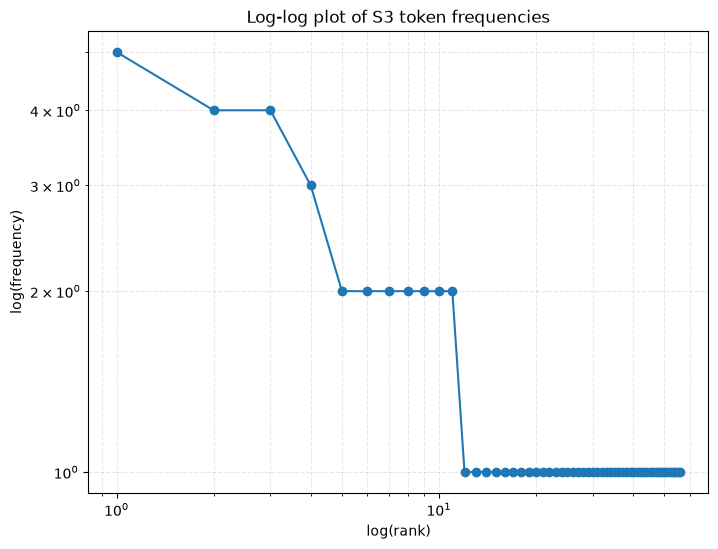

Top 5 S1 bigrams: [(('.', 'it'), 5), (('.', 'i'), 5), (('it', 'works'), 4), (('works', 'on'), 4), (('on', 'another'), 4)]
Top 5 S3 bigrams: [(('works', 'another'), 4), (('another', 'computer'), 4), (('computer', 'locked'), 2), (('use', 'mobile'), 2), (('mobile', 'hotspot'), 2)]


In [14]:
from collections import Counter
import matplotlib.pyplot as plt

all_s1 = [t.lower() for _, row in df.iterrows() for t in word_tokenize(row["Ticket_Text"])]
all_s2 = [t for t in all_s1 if not is_punct(t)]
all_s3 = [t for _, row in df.iterrows() for t in process_ticket(row["Ticket_Text"])["final"]]
all_s4 = [porter.stem(t) for t in all_s3]

stats = {
    "S1": {"tokens": len(all_s1), "unique_tokens": len(set(all_s1)), "TTR": len(set(all_s1)) / len(all_s1) if all_s1 else 0},
    "S2": {"tokens": len(all_s2), "unique_tokens": len(set(all_s2)), "TTR": len(set(all_s2)) / len(all_s2) if all_s2 else 0},
    "S3": {"tokens": len(all_s3), "unique_tokens": len(set(all_s3)), "TTR": len(set(all_s3)) / len(all_s3) if all_s3 else 0},
    "S4": {"tokens": len(all_s4), "unique_tokens": len(set(all_s4)), "TTR": len(set(all_s4)) / len(all_s4) if all_s4 else 0},
}

stats_df = pd.DataFrame.from_dict(stats, orient="index")
stats_df

print("Top 10 S1 words:", Counter(all_s1).most_common(10))
print("Top 10 S3 words:", Counter(all_s3).most_common(10))

freq = Counter(all_s3)
ranked = sorted(freq.values(), reverse=True)
log_ranks = [float(i) for i in range(1, len(ranked) + 1)]
log_freq = [float(x) for x in ranked]

plt.figure(figsize=(8, 6))
plt.loglog(log_ranks, log_freq, 'o-')
plt.xlabel('log(rank)')
plt.ylabel('log(frequency)')
plt.title('Log-log plot of S3 token frequencies')
plt.grid(True, which='both', ls='--', alpha=0.3)
plt.show()

print("Top 5 S1 bigrams:", Counter(nltk.bigrams(all_s1)).most_common(5))
print("Top 5 S3 bigrams:", Counter(nltk.bigrams(all_s3)).most_common(5))


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*
TTR drops from S1 to S4 because stemming collapses many surface forms into one root form. In this dataset, words like `works`, `working`, `opening`, `running`, and `occurs` are reduced to common stems, so the number of unique tokens decreases while the total token count stays similar. For this corpus, the TTR is about 0.52 in S1, 0.75 in S3, and 0.71 in S4; the reduction in unique forms is what changes the ratio.
